# Notebook 3: Treino, Modelação e Otimização de Hiperparâmetros

**Unidade Curricular:** Dados e Aprendizagem Automática (DAA) — 2026/2027

Neste notebook treinamos e avaliamos modelos para prever a faixa etária (`AGE_RANGE`), usando os dados finais do Notebook 2. A métrica é o **Macro F1**, a mesma da competição. O percurso é o seguinte:

1. Um **modelo de referência** simples (árvore de decisão);
2. A **comparação de vários classificadores** nas mesmas condições;
3. A **otimização** do melhor modelo;
4. A **análise dos erros** do modelo final;
5. A **submissão final** e o registo de todas as submissões e experiências.

## 1. Configuração e Carregamento dos Dados

Importamos as bibliotecas, carregamos os dados finais do Notebook 2 e definimos os elementos comuns a todo o notebook:

- a **validação cruzada estratificada em 5 partes** (sempre as mesmas partes, para que as comparações entre modelos sejam justas);
- a **faixa mínima** de cada pessoa (Notebook 2, secção 6), usada para corrigir previsões impossíveis;
- a função que gera o ficheiro de submissão no formato do Kaggle.

In [1]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict, RandomizedSearchCV
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

warnings.filterwarnings('ignore', category=FutureWarning)
plt.style.use('ggplot')

DATA_DIR = '../data'
SUBMISSIONS_DIR = '../submissions'
TARGET = 'AGE_RANGE'
RANDOM_STATE = 42
AGE_LABELS = ['15-17', '18-19', '20-24', '25-29', '30-34', '35-39', '40-44', '45-49',
              '50-54', '55-59', '60-64', '65-69', '70-74', '75-79', '80-84', '85+']

# Dados finais do Notebook 2
train_df = pd.read_csv(os.path.join(DATA_DIR, 'train_nb02.csv'), index_col='PID')
test_df = pd.read_csv(os.path.join(DATA_DIR, 'test_nb02.csv'), index_col='PID')
X = train_df.drop(columns=TARGET)
y = train_df[TARGET]
X_test = test_df[X.columns]

# Faixa mínima de cada pessoa (para a correção das previsões)
faixa_min = X['FAIXA_MINIMA'].values
faixa_min_test = X_test['FAIXA_MINIMA'].values

# Validação cruzada (sempre as mesmas 5 partes)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def gerar_submissao(previsoes, nome):
    """Gera o CSV de submissão a partir do ficheiro de exemplo do Kaggle (RowId + AGE_RANGE)."""
    submissao = pd.read_csv(os.path.join(DATA_DIR, 'example_submission_10.csv'))
    assert len(submissao) == len(previsoes) == 3655, "O nº de linhas não coincide"
    submissao[TARGET] = previsoes
    caminho = os.path.join(SUBMISSIONS_DIR, nome)
    submissao.to_csv(caminho, index=False)
    print(f"Submissão guardada em {caminho}")


print(f"X: {X.shape} | y: {y.shape} | X_test: {X_test.shape}")

X: (10962, 339) | y: (10962,) | X_test: (3655, 339)


## 2. Modelo de Referência: Árvore de Decisão

Começamos por um modelo simples e interpretável, que serve de referência para os seguintes. Treinamos uma árvore de decisão com `class_weight='balanced'`, que dá mais peso às faixas etárias menos representadas (importante para o Macro F1), e testamos várias profundidades máximas: uma árvore demasiado curta não capta os padrões (*underfitting*), e uma demasiado profunda memoriza o treino (*overfitting*).

,max_depth,Macro F1,Desvio padrão
0,4,0.3090,0.0082
1,6,0.3806,0.0153
2,8,0.4072,0.0057
3,10,0.4035,0.0102
4,12,0.3922,0.0100
5,15,0.3761,0.0085
6,None,0.3662,0.0114


Melhor profundidade: 8 (Macro F1 = 0.4072)


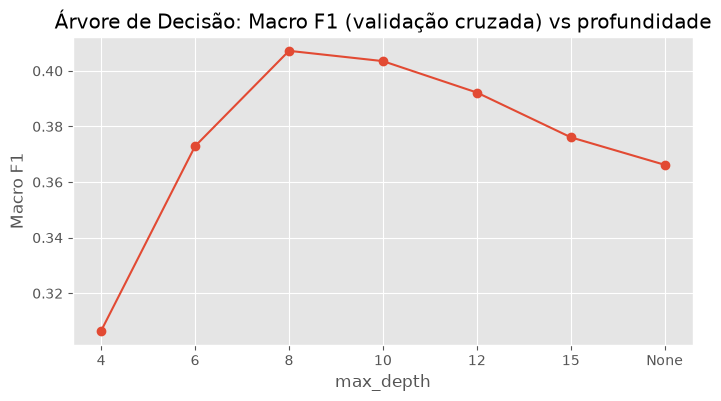

In [2]:
resultados = []
for profundidade in [4, 6, 8, 10, 12, 15, None]:
    arvore = DecisionTreeClassifier(max_depth=profundidade, class_weight='balanced',
                                    random_state=RANDOM_STATE)
    notas = cross_val_score(arvore, X, y, cv=cv, scoring='f1_macro')
    resultados.append({'max_depth': str(profundidade), 'Macro F1': notas.mean(), 'Desvio padrão': notas.std()})

resultados_df = pd.DataFrame(resultados).round(4)
display(resultados_df)

resultados_df.plot(x='max_depth', y='Macro F1', marker='o', legend=False, figsize=(8, 4),
                   title='Árvore de Decisão: Macro F1 (validação cruzada) vs profundidade')
plt.ylabel('Macro F1')
plt.show()

> **Conclusão:** o melhor resultado é obtido com `max_depth=8` (Macro F1 = 0,404 ± 0,013), cerca de sete vezes acima do classificador aleatório (0,06). Profundidades menores levam a *underfitting* (0,309 com profundidade 4) e maiores a *overfitting*, com o desempenho a descer até 0,370 numa árvore sem limite. Este valor é a **referência** para os modelos seguintes.

## 3. Comparação de Modelos de Classificação

Comparamos sete classificadores nas mesmas condições (mesmos dados, mesma validação cruzada), com parâmetros base razoáveis:

- **Árvore de Decisão**: `max_depth=8`, a melhor profundidade da secção 2;
- **Regressão Logística**: atribui um peso a cada variável; requer **normalização** (`StandardScaler`), dado que as variáveis têm escalas muito diferentes, e usa `C=0.01` (regularização), o melhor valor entre {0,01; 0,1; 1};
- **Naive Bayes**: probabilidade de cada faixa assumindo independência entre variáveis;
- **KNN**: faixa mais frequente entre as 15 pessoas mais semelhantes do treino (com normalização);
- **SVM**: fronteiras de separação entre faixas com margem máxima (com normalização);
- **Random Forest**: votação de 300 árvores, cada uma treinada com amostras aleatórias de pessoas e variáveis;
- **Gradient Boosting**: árvores construídas em sequência, cada uma a corrigir os erros das anteriores.

A normalização é incluída num *pipeline*, para que em cada parte da validação cruzada seja calculada apenas com os dados de treino dessa parte, evitando fuga de informação.

**Correção pela idade mínima.** A `FAIXA_MINIMA` (Notebook 2, secção 6) é um limite rígido: uma pessoa nunca pode pertencer a uma faixa inferior. Após a previsão, sempre que a faixa prevista é inferior à faixa mínima, é substituída por esta. Para cada modelo apresentamos o Macro F1 com e sem esta correção, calculado sobre as previsões de validação cruzada de todas as pessoas (`cross_val_predict`).

In [3]:
modelos = {
    'Árvore de Decisão': DecisionTreeClassifier(max_depth=8, class_weight='balanced', random_state=RANDOM_STATE),
    'Regressão Logística': make_pipeline(StandardScaler(),
                                         LogisticRegression(C=0.01, class_weight='balanced', max_iter=2000,
                                                            random_state=RANDOM_STATE)),
    'Naive Bayes': GaussianNB(),
    'KNN (k=15)': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
    'SVM': make_pipeline(StandardScaler(), SVC(class_weight='balanced', random_state=RANDOM_STATE)),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight='balanced',
                                            n_jobs=-1, random_state=RANDOM_STATE),
    'Gradient Boosting': HistGradientBoostingClassifier(class_weight='balanced', random_state=RANDOM_STATE),
}

comparacao = []
for nome, modelo in modelos.items():
    inicio = time.time()
    prev = cross_val_predict(modelo, X, y, cv=cv, n_jobs=-1)
    comparacao.append({'Modelo': nome,
                       'Macro F1': f1_score(y, prev, average='macro'),
                       'Macro F1 (com correção)': f1_score(y, np.maximum(prev, faixa_min), average='macro'),
                       'Previsões corrigidas': (prev < faixa_min).sum(),
                       'Tempo (s)': time.time() - inicio})
    print(f"{nome}: concluído em {time.time() - inicio:.0f} s")

comparacao_df = pd.DataFrame(comparacao).sort_values('Macro F1 (com correção)', ascending=False).round(4)
display(comparacao_df)

Árvore de Decisão: concluído em 2 s
Regressão Logística: concluído em 3 s
Naive Bayes: concluído em 1 s
KNN (k=15): concluído em 2 s
SVM: concluído em 15 s
Random Forest: concluído em 3 s
Gradient Boosting: concluído em 50 s


,Modelo,Macro F1,Macro F1 (com correção),Previsões corrigidas,Tempo (s)
6,Gradient Boosting,0.4668,0.4670,7,49.8438
5,Random Forest,0.4497,0.4516,30,3.1794
1,Regressão Logística,0.4272,0.4362,141,2.5440
4,SVM,0.4201,0.4272,113,14.6394
0,Árvore de Decisão,0.4071,0.4116,74,2.1462
3,KNN (k=15),0.2939,0.3062,240,1.5488
2,Naive Bayes,0.2726,0.2808,165,1.1562


> **Conclusão:** o **Gradient Boosting** obtém o melhor resultado (Macro F1 = 0,467), seguido do Random Forest (0,450); ambos superam a Regressão Logística com correção (0,436) e a árvore de decisão (0,412). Os modelos baseados em conjuntos de árvores reduzem a instabilidade de uma árvore única.
>
> A correção pela idade mínima beneficia sobretudo os modelos que mais previsões impossíveis fazem: 141 na Regressão Logística (+0,009) e 240 no KNN (+0,012). O Gradient Boosting faz apenas 7, por aprender por si próprio estes limites, pelo que a correção quase não o altera (+0,0002). A correção é mantida no modelo final por ser inofensiva e garantir previsões coerentes.
>
> O KNN (0,306) e o Naive Bayes (0,281) têm o pior desempenho: o KNN dá o mesmo peso às 339 variáveis no cálculo da semelhança, pelo que as irrelevantes se sobrepõem às informativas; o Naive Bayes assume independência entre variáveis, pressuposto violado pelas muitas variáveis redundantes (ex.: as perguntas de autonomia).
>
> O **Gradient Boosting** é selecionado para otimização.

## 4. Otimização do Gradient Boosting

Cada avaliação do Gradient Boosting demora quase um minuto, pelo que uma pesquisa exaustiva de hiperparâmetros seria impraticável. Usamos duas estratégias:

- **`RandomizedSearchCV`**: em vez de testar todas as combinações da grelha, testa 12 escolhidas aleatoriamente;
- **Paragem antecipada** (`early_stopping`): o número de árvores é escolhido automaticamente, parando quando o desempenho numa parte de validação interna (10% do treino) deixa de melhorar durante 20 iterações.

Otimizamos:

| Hiperparâmetro | O que controla | Valores testados |
|---|---|---|
| `learning_rate` | quanto cada nova árvore corrige as anteriores | 0,03; 0,05; 0,1; 0,2 |
| `max_leaf_nodes` | tamanho de cada árvore (nº máximo de folhas) | 15; 31; 63 |
| `min_samples_leaf` | nº mínimo de pessoas por folha | 10; 20; 50 |
| `l2_regularization` | penalização de correções excessivas | 0; 0,1; 1; 10 |

In [48]:
gb_base = HistGradientBoostingClassifier(max_iter=500, early_stopping=True, validation_fraction=0.1,
                                         n_iter_no_change=20, class_weight='balanced',
                                         random_state=RANDOM_STATE)
distribuicao = {
    'learning_rate': [0.03, 0.05, 0.1, 0.2],
    'max_leaf_nodes': [15, 31, 63],
    'min_samples_leaf': [10, 20, 50],
    'l2_regularization': [0, 0.1, 1, 10],
}

inicio = time.time()
pesquisa_gb = RandomizedSearchCV(gb_base, distribuicao, n_iter=12, cv=cv, scoring='f1_macro',
                                 n_jobs=-1, random_state=RANDOM_STATE)
pesquisa_gb.fit(X, y)
print(f"Tempo total: {(time.time() - inicio) / 60:.1f} min")

MELHORES_PARAMS_GB = pesquisa_gb.best_params_
print(f"Melhores parâmetros: {MELHORES_PARAMS_GB}")
print(f"Melhor Macro F1 (validação cruzada): {pesquisa_gb.best_score_:.4f}")
print(f"Nº de árvores escolhido pela paragem antecipada: {pesquisa_gb.best_estimator_.n_iter_}")

display(pd.DataFrame(pesquisa_gb.cv_results_)
        [['param_learning_rate', 'param_max_leaf_nodes', 'param_min_samples_leaf',
          'param_l2_regularization', 'mean_test_score', 'std_test_score']]
        .sort_values('mean_test_score', ascending=False).round(4))

Tempo total: 5.8 min
Melhores parâmetros: {'min_samples_leaf': 20, 'max_leaf_nodes': 15, 'learning_rate': 0.05, 'l2_regularization': 1}
Melhor Macro F1 (validação cruzada): 0.4742
Nº de árvores escolhido pela paragem antecipada: 156


,param_learning_rate,param_max_leaf_nodes,param_min_samples_leaf,param_l2_regularization,mean_test_score,std_test_score
2,0.05,15,20,1.0,0.4742,0.0073
0,0.05,15,10,10.0,0.4731,0.0053
4,0.10,15,50,0.1,0.4637,0.0078
11,0.03,63,10,1.0,0.4618,0.0067
9,0.10,15,10,0.0,0.4589,0.0116
5,0.05,31,10,0.0,0.4581,0.0035
7,0.20,15,50,0.1,0.4570,0.0090
6,0.10,63,10,10.0,0.4567,0.0074
10,0.05,63,10,0.1,0.4556,0.0051
8,0.20,31,10,0.1,0.4552,0.0120


> **Conclusão:** a melhor configuração (`learning_rate=0.05`, `max_leaf_nodes=15`, `min_samples_leaf=20`, `l2_regularization=1`, com 156 árvores escolhidas pela paragem antecipada) obtém um Macro F1 de 0,474 ± 0,007, face a 0,467 com os parâmetros por defeito.
>
> As duas melhores combinações partilham árvores pequenas, taxa de aprendizagem baixa e regularização, enquanto as configurações com árvores maiores (63 folhas) ou sem regularização obtêm resultados inferiores: para estes dados, um modelo construído com muitas correções pequenas e regularizadas generaliza melhor. Uma segunda pesquisa, mais fina, em torno desta configuração não trouxe melhoria (0,4747), pelo que esta é mantida.

## 5. Análise de Erros do Modelo Final

Analisamos os erros do modelo final (Gradient Boosting otimizado, com correção pela idade mínima), usando previsões obtidas por validação cruzada (`cross_val_predict`): cada pessoa é prevista por um modelo treinado sem ela, o que garante uma avaliação honesta.

Analisamos:
- a **matriz de confusão** normalizada por linha (percentagem de cada faixa verdadeira atribuída a cada faixa prevista; a diagonal corresponde aos acertos);
- o **F1 de cada faixa**, já que o Macro F1 é a sua média simples;
- a **distância dos erros**: se ocorrem entre faixas vizinhas ou distantes, e se cruzam o limite dos 55 anos.

Macro F1 do modelo final (validação cruzada): 0.4752


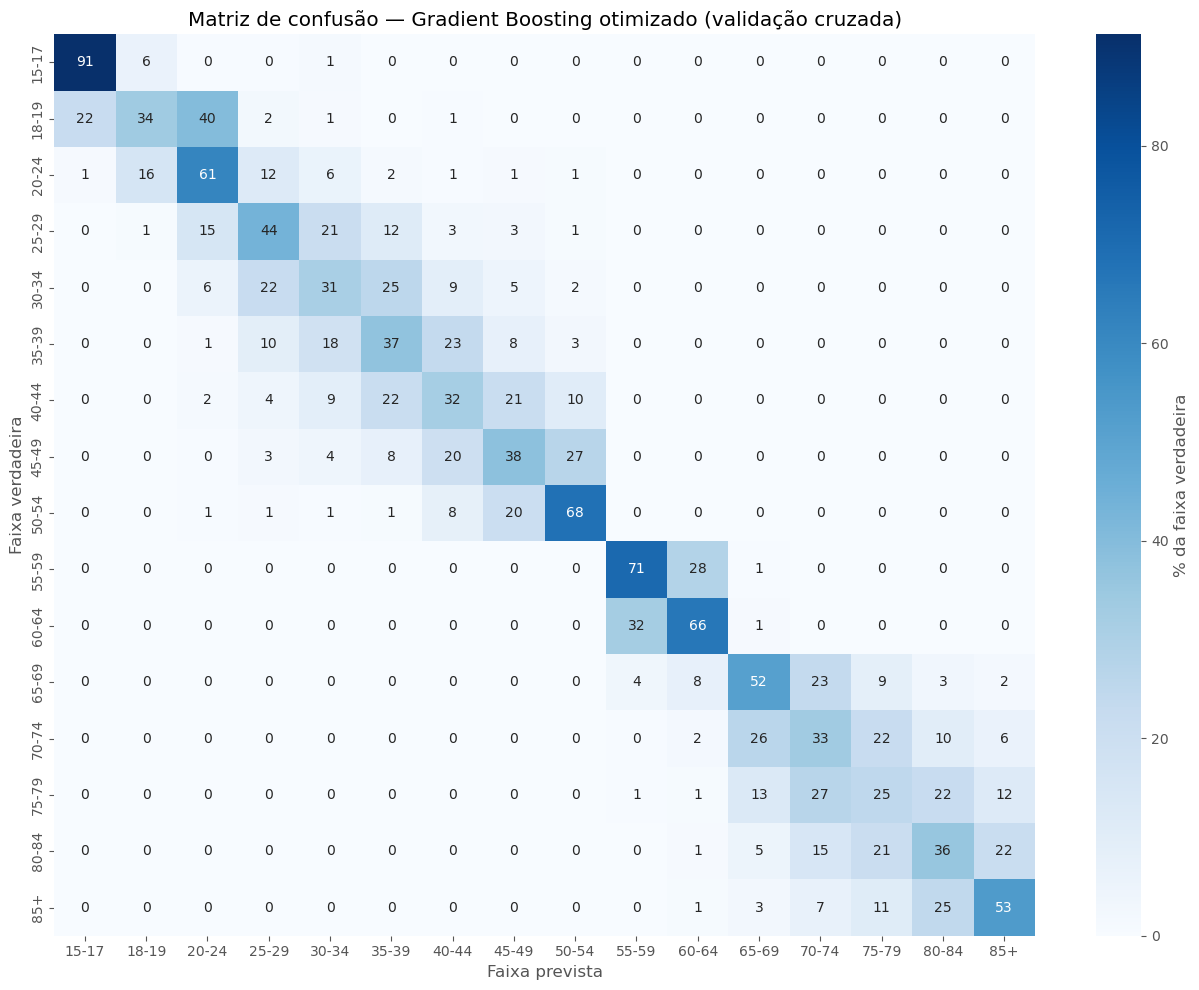

,Faixa,Nº pessoas,F1
0,15-17,207,0.855
1,18-19,172,0.371
2,20-24,399,0.593
3,25-29,377,0.400
4,30-34,449,0.299
5,35-39,647,0.369
6,40-44,859,0.345
7,45-49,862,0.397
8,50-54,905,0.658
9,55-59,1014,0.679


Acerto exato:                47.9%
Erro de 1 faixa (vizinha):   37.0%
Erro de 2 faixas:            10.7%
Erro de 3 ou mais faixas:    4.4%
Erros que cruzam os 55 anos: 5 pessoas (0.0%)


In [49]:
gb_final = HistGradientBoostingClassifier(max_iter=500, early_stopping=True, validation_fraction=0.1,
                                          n_iter_no_change=20, class_weight='balanced',
                                          random_state=RANDOM_STATE, **MELHORES_PARAMS_GB)

prev_cv = cross_val_predict(gb_final, X, y, cv=cv, n_jobs=-1)
prev_cv = np.maximum(prev_cv, faixa_min)          # correção pela idade mínima
print(f"Macro F1 do modelo final (validação cruzada): {f1_score(y, prev_cv, average='macro'):.4f}")

# 1) Matriz de confusão (% por faixa verdadeira)
matriz = confusion_matrix(y, prev_cv, normalize='true') * 100
plt.figure(figsize=(13, 10))
sns.heatmap(matriz, annot=True, fmt='.0f', cmap='Blues',
            xticklabels=AGE_LABELS, yticklabels=AGE_LABELS, cbar_kws={'label': '% da faixa verdadeira'})
plt.xlabel('Faixa prevista')
plt.ylabel('Faixa verdadeira')
plt.title('Matriz de confusão — Gradient Boosting otimizado (validação cruzada)')
plt.tight_layout()
plt.show()

# 2) F1 por faixa
f1_faixa = pd.DataFrame({'Faixa': AGE_LABELS,
                         'Nº pessoas': y.value_counts().sort_index().values,
                         'F1': f1_score(y, prev_cv, average=None).round(3)})
display(f1_faixa)

# 3) Distância dos erros
distancia = np.abs(prev_cv - y.values)
cruza_55 = (prev_cv >= 9) != (y.values >= 9)
print(f"Acerto exato:                {(distancia == 0).mean():.1%}")
print(f"Erro de 1 faixa (vizinha):   {(distancia == 1).mean():.1%}")
print(f"Erro de 2 faixas:            {(distancia == 2).mean():.1%}")
print(f"Erro de 3 ou mais faixas:    {(distancia >= 3).mean():.1%}")
print(f"Erros que cruzam os 55 anos: {cruza_55.sum()} pessoas ({cruza_55.mean():.1%})")

> **Conclusão:** o modelo final obtém um Macro F1 de 0,475. Acerta exatamente em 47,9% dos casos e 84,9% das previsões ficam a no máximo uma faixa da verdadeira; apenas 4,4% erram por três ou mais faixas, e só 5 pessoas são colocadas do lado errado do limite dos 55 anos.
>
> O F1 é mais elevado nas faixas junto a uma fronteira, que têm apenas um vizinho com que se confundir: 15-17 (0,86), 55-59 (0,68), 50-54 (0,66) e 60-64 (0,65). É mais baixo nas faixas intermédias de cada grupo, em especial 75-79 (0,27) e 30-34 (0,30), cujos perfis de saúde e estilo de vida são muito semelhantes aos das faixas vizinhas. A faixa 18-19 é frequentemente confundida com 20-24 (40%) e 15-17 (22%), o que reflete uma fase de transição (fim dos estudos secundários) que dura apenas dois anos.
>
> Face à Regressão Logística, o Gradient Boosting melhora o F1 de todas as faixas, com os maiores ganhos em 15-17, 20-24 e 65-69.

## 6. Modelo Final e Submissão

O modelo final é o **Gradient Boosting** com os hiperparâmetros da secção 4, treinado com todo o conjunto de treino. As previsões para o teste são corrigidas pela idade mínima e guardadas no formato da competição.

In [50]:
gb_final.fit(X, y)
previsoes_teste = np.maximum(gb_final.predict(X_test), faixa_min_test)

print(f"Nº de árvores do modelo final: {gb_final.n_iter_}")
print(f"Previsões corrigidas pela idade mínima: {(gb_final.predict(X_test) < faixa_min_test).sum()}")

# Comparação da distribuição das previsões com a do treino
distribuicao = pd.DataFrame({
    'Treino (%)': y.value_counts(normalize=True).sort_index().values * 100,
    'Previsões no teste (%)': pd.Series(previsoes_teste).value_counts(normalize=True)
                                .reindex(range(16), fill_value=0).values * 100,
}, index=AGE_LABELS).round(1)
display(distribuicao)

gerar_submissao(previsoes_teste, 'sub04_gradient_boosting_otimizado.csv')

Nº de árvores do modelo final: 156
Previsões corrigidas pela idade mínima: 5


,Treino (%),Previsões no teste (%)
15-17,1.9,1.7
18-19,1.6,1.5
20-24,3.6,3.9
25-29,3.4,4.4
30-34,4.1,4.9
35-39,5.9,5.4
40-44,7.8,6.6
45-49,7.9,8.1
50-54,8.3,8.0
55-59,9.3,10.4


Submissão guardada em ../submissions/sub04_gradient_boosting_otimizado.csv


> **Conclusão:** o modelo final (156 árvores) faz apenas 5 previsões no teste abaixo da idade mínima, que são corrigidas. As previsões distribuem-se pelas 16 faixas em proporções semelhantes às do treino (diferença máxima de 1,1 pontos percentuais, na faixa 55-59), sem nenhuma faixa ignorada. O ficheiro `sub04_gradient_boosting_otimizado.csv` constitui a submissão do modelo final.

## 7. Registo de Submissões e Experiências

### 7.1 Submissões

| # | Data | Modelo | Macro F1 (validação) | Macro F1 (Kaggle) |
|---|---|---|---|---|
| 1 | 25/10/2026 | Árvore de decisão (`max_depth=8`) | 0,407 | 0,40 |
| 2 | 26/10/2026 | Regressão Logística (`C=0.01`), com contagens | 0,426 | 0,43 |
| 3 | 26/10/2026 | Gradient Boosting (parâmetros por defeito) + correção | 0,467 | 0,46 |
| 4 | 27/10/2026 | Gradient Boosting otimizado + correção (**modelo final**) | 0,475 | ... |

As submissões 1 a 3 foram feitas com versões intermédias dos dados (antes da seleção de features e da idade mínima). Em todas, o resultado no Kaggle ficou a menos de 0,01 da validação cruzada, o que confirma a fiabilidade desta avaliação.

### 7.2 Experiências não adotadas

| Experiência | Resultado | Razão para não adotar |
|---|---|---|
| Otimização da árvore de decisão (`GridSearchCV`: `criterion`, `max_depth`, `min_samples_leaf`) | 0,403–0,411 | Sem ganho face à referência; a árvore única estabiliza em ~0,40 |
| Dois modelos de Regressão Logística (menos de 55 / 55 ou mais, separados pela `HA1A`) | 0,428 vs. 0,426 | Diferença dentro do ruído: o modelo único só colocava 10 pessoas do lado errado dos 55 anos |
| Pesquisa refinada do Gradient Boosting (árvores de 7–20 folhas, mais regularização) | 0,4747 vs. 0,4742 | Sem ganho: a configuração da secção 4 já está próxima do ótimo |
| Votação suave (Gradient Boosting + Random Forest + Regressão Logística) | 0,472 vs. 0,475 | Os modelos mais fracos degradam as previsões do melhor |
| Idade mínima alargada (escolaridade e tipo de agregado) | 0,4698 vs. 0,4705 | Regras de uma só variável, que o Gradient Boosting já aprende |